# **Лабораторная работа №1**

### Цель работы
Целью выполнения лабораторной работы является знакомство с базовыми принципами работы АЦП; дискретными сигналами; способами их обработки с помощью дискретных систем.

---
## __Язык Julia и Engee__

### Использование языка Julia

#### Использование Julia в Engee (предпочтительный способ)
1. Зарегистрироваться на сайте [Engee](https://engee.com)
2. Получить бесплатную лицензию указав СПбГЭТУ "ЛЭТИ" в качестве организации
#### Использование Julia в Сolab
Change runtime type -> Julia
#### Использование Julia в VS Code
Открыть раздел Extensions и найти расширение Julia от Julia Language Support (julialang.language-julia). Установить его.

### Базовые конструкции языка Julia

Работа с диапазонами

In [9]:
# Диапазон
t = 0 : 0.01 : 100
println(t)
println(typeof(t))
# Начало диапазона
println(t[1])
# Конец диапазона
println(t[end])
# Поддиапазон
println(t[1:5])
# Преобразование в вектор
v = collect(t[1:5])
println(v)
println(typeof(v))


0.0:0.01:100.0
StepRangeLen{Float64, Base.TwicePrecision{Float64}, Base.TwicePrecision{Float64}, Int64}
0.0
100.0
0.0:0.01:0.04
[0.0, 0.01, 0.02, 0.03, 0.04]
Vector{Float64}


Инициализация и применение функций

In [10]:
# Определение функции
function foo(a, b)
  return a^2 + 2*a*b + b^2
end

# Определение с помощью анонимной функции
foo_lambda = (x, y) -> x^2 + 2*x*y + y^2

# Применениие операторов к векторам
println(5 .^ [1,2,3,4])

# Применение функций к скалярам
println(foo(1,2))

# Применение функций к векторам
println(sin.([1,2,3,4]))
println(foo.([1,2], [2,1]))

[5, 25, 125, 625]
9
[0.8414709848078965, 0.9092974268256817, 0.1411200080598672, -0.7568024953079282]
[9, 9]


Подключение пакетов для работы с изображениями

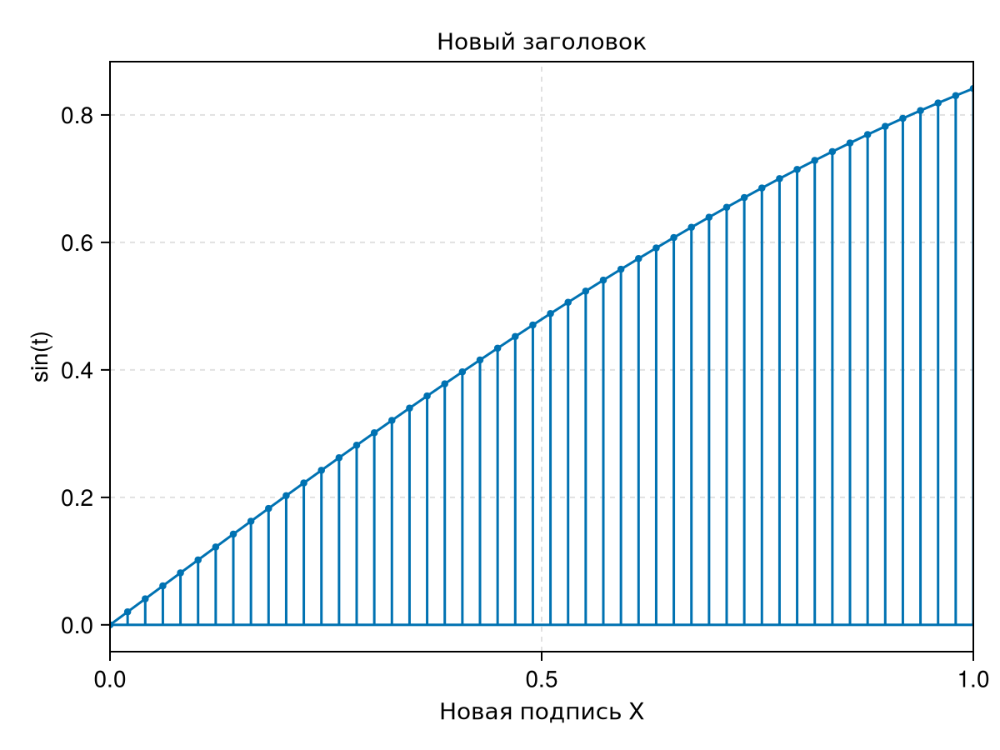

In [11]:
using CairoMakie

# 1. Define the independent variable and function
t = range(0, 1, length=50)   # 50 points from 0 to 1
x = sin.(t)

# 2. Create a figure and axis with labels, title, and grid
fig = Figure()
ax = Axis(fig[1, 1],
    xlabel = "Новая подпись X",
    ylabel = "sin(t)",
    title = "Новый заголовок",
    xgridstyle = :dash,      # enable grid lines
    ygridstyle = :dash
)

# 3. Plot the line
lines!(ax, t, x)

# 4. Set axis limits
xlims!(ax, 0, 1)

# 5. Add a stem plot on the same axis
stem!(ax, t, x; offset = 0, marker = :circle, markersize = 6)

# 6. Display the figure
fig

### Моделирование дискретных LTI систем в Engee

Для моделирования (дискретных систем в том числе) в Engee реализован такой объект как ``модель``. В первом приближении ``модель`` представляет из себя некоторое множество функциональных блоков, расположенных на холсте и соединенных между собой. Для анализа протекающих в системе процессов используются специальные блоки, например осциллограф.
Далее будет кратко рассмотрены блоки, необходимые для выполнения лабораторной работы.

* Блоки хранятся в библиотеке и перетаскиваются оттуда на холст
<img src="https://drive.google.com/uc?id=12jUGrBzY58oYjlYiHFOildh7z6kzQR0L" width="200"/>


* Выходом блока ``Discrete Impulse`` является дискретный импульс
<img src="https://drive.google.com/uc?id=1n0jg8GBMipCnW2__BiwU8h0OPmoB6EUT" width="300"/>

* ``Осциллограф`` является одним из инструментов графического вывода сигналов.
<img src="https://drive.google.com/uc?id=1wzRYRW_LkjCYJNi_Pr3u5UCIJIYhq_E0" width="200"/>

* Базовые блоки сложения и умножения
<img src="https://drive.google.com/uc?id=1EYPvkM_mzG_qe7XVf6g1hLQlrFIrr9W3" width="300"/>
<img src="https://drive.google.com/uc?id=1iamqz9kf2EgvgLIFNxTO0oZMmPMI4p0f" width="265"/>


3. Блок запаздывания
<img src="https://drive.google.com/uc?id=1El0yGwDEtx_-C6hNqqz8weFm7kJ10fOx" width="250"/>
<img src="https://drive.google.com/uc?id=1TP_K8-MUjPVZN0kTF7c28OZKdDbT5zcM" width="350"/>



---
## __Теоретическая часть__

### 1. Аналого-цифровой преобразователь



Уравнение АЦП для входного аналогового сигнала $x(t)$, измеряющего сигнал в пределах от $[U_{min},U_{max}]$ :

 $$ { x_{\text{D}}[n] = \Big\lfloor \frac{x_{\text{A}}(nT_s)}{(U_{max} - U_{\text{min}})} \cdot 2^{M}   }\Big\rfloor \tag{1}$$

$$ x^*_{D} = \min(\max(x_{D}[n],0), 2^M-1) \tag{1*} $$

где $n \space -$ аргумент дискретного времени, $T_s \space - $ период дискретизации, $x_{\text{D}}[n] \in [0, 2^M - 1]$ — целое двоичное число на выходе АЦП разрядностью M бит.

$$ x[n] = x_{\text{D}}[n] \cdot \frac{(U_{max} - U_{\text{nax}})}{2^M}  \tag{2}$$

$$ x^*_{D} = \min(\max(x[n],0), U_{max}-ΔU) \tag{2*} $$

Количество уровней квантования и шаг квантования:

$$
L = 2^M,\tag{3}
$$  

$$
\Delta U = \frac{U_{\max}-U_{\min}}{2^M}. \tag{4}
$$

### 2. Свертка


#### 2.1. Свертка непрерывных функций
Свёрткой двух непрерывных функций $f(t)$ и $g(t)$ называется функция:
$$
y(t) = (f * g)(t) = \int_{-\infty}^{\infty} f(\tau)\, g(t - \tau)\, d\tau
\tag{5}$$
**Свойства оператора свертки:**
- Коммутативность: $x * h = h * x$
- Ассоциативность: $(x * h) * g = x * (h * g)$
- Дистрибутивность: $x * (h + g) = x * h + x * g$
- Сдвиг: если $y(t)=x(t)*h(t)$, то $x(t-t_0)*h(t) = y(t-t_0)$
- Свёртка с $\delta$-функцией: $x(t) * \delta(t - t_0) = x(t - t_0)$

#### 2.2. Свертка дискретных функций

Для последовательностей $x[n]$ и $h[n]$:

$$
y[n] = (x * h)[n] = \sum_{k=-\infty}^{\infty} x[k]\, h[n - k]
\tag{6}$$

Для конечных последовательностей длин $N$ и $M$ результат имеет длину $N + M - 1$:  

$$x = x[n],\space n\in[1,..,N]$$

$$h = h[m],\space m\in[1,..,M]$$

$$ y[n] = \sum_{k=1}^{N+M-1} x[k]\, h[n - k] \tag{7}$$



### 3. Корреляция

#### 3.1. Корреляция непрерывных функций

Взаимная корреляция двух вещественных сигналов:

$$
R_{xh}(\tau) = (f \star g)(\tau) = \int_{-\infty}^{\infty} f(t)\, g(\tau + t)\, dt
$$


Автокорреляция ($h = x$):

$$
R_{xx}(\tau) = \int_{-\infty}^{\infty} x(t)\, x(t + \tau)\, dt
$$

#### 3.2. Корреляция дискретных функций
Взаимная корреляция:

$$
R_{xh}[m] = \sum_{n=-\infty}^{\infty} x[n]\, h[n - m]
$$

Автокорреляция:

$$
R_{xx}[m] = \sum_{n=-\infty}^{\infty} x[n]\, x[n - m]
$$

### 4. Аналоговые и дискретные системы

#### 4.1. Аналоговые системы
Аналоговая система — это объект, которое преобразует непрерывный входной сигнал $x(t)$ в непрерывный выходной сигнал $y(t)$. Эту зависимость можно описать с помощью ассоциированного с системой оператора $F$:
$$
y(t) = F\{x(t)\}, \qquad t \in \mathbb{R}
$$
Вход и выход определены для любого момента времени $t$, а сами сигналы описываются непрерывными функциями.
Часто для описания поведения аналоговых систем во времени используется аппарат дифференциальных уравнений.

#### 4.2. Дискретные системы
Дискретная система — это объект, которое дискретную сигнал $x[n]$ в дискретную сигнал $y[n]$, который так же можно описать с помощью оператора $F$:
$$
y[n] = F\{x[n]\}, \qquad n \in \mathbb{Z}
$$
Часто для описания дискретных систем используется аппарат разностных уравнений.

### 2.3. Линейные инвариантные во времени системы

- Линейность:

$$
F\{\alpha x_1 + \beta x_2\} = \alpha\,F\{x_1\} + \beta\,F\{x_2\}
$$

- Инвариантность во времени:

$$
y(t) = F\{x(t)\} \;\Rightarrow\; y(t - t_0) = F\{x(t - t_0)\}
$$

Система, обладающая обоими свойствами — ЛИВ-система (LTI — Linear Time-Invariant).

Аналоговые и дискретные LTI-системы описываются с помощью линейных дифференциальных уравнений и линейных разностных уравнений соответственно.

Общий вид линейного дифференциального уравнения $N$-го порядка:

$$
\sum_{k=0}^{N} a_k\, \frac{d^k y(t)}{dt^k} = \sum_{m=0}^{M} b_m\, \frac{d^m x(t)}{dt^m}
$$

Общий вид линейного разностного уравнения $N$-го порядка:

$$
\sum_{k=0}^{N} a_k\, y[n-k] = \sum_{m=0}^{M} b_m\, x[n-m]
$$

---
## __Практическая часть__

### 1 Неделя (8.09.26 - 14.09.26)



### 1.1. Оцифровка аналогового сигнала

Даны следующие аналоговые сигналы:


1. Единичный импульс (дельта-функция Дирака)
  $$ \delta(t) =
\begin{cases}
+\infty, & t = 0 \\
0, & t \neq 0
\end{cases} $$

$$\int_{-∞}^{∞} \delta(t) dt = 1$$



2. Постоянный сигнал
  
$$ x(t) = a_i*H(t) $$
&emsp;&emsp; где $a_1 = 1, a_2 = 2$

3. Экспоненциальный сигнал
$$x(t) =  a_ie^{λ_it}$$
где:
* $a_1 = 2,\space \lambda_1 = -0.5$
* $a_2 = 4,\space \lambda_2 = 0.5$

4.  Гармонический сигнал
$$ x(t) = a_i \cdot \sin(2\pi f_i t + ϕ_i) $$
где:
* $a_1 = 0.5,\space f_1=1, \space ϕ_1 =0  $
* $a_2 = 5,\space f_2=100, \space ϕ_2 =0  $
* $a_3 = 1,\space f_3=0.1, \space ϕ_3 =pi/4  $
5. Полигармонический сигнал
$$ x(t) =\cos(2\pi \cdot 1 \cdot t) \;+\; 0.5 \cdot \cos(2\pi \cdot 3 \cdot t) \;+\; 0.2 \cdot \cos(2\pi \cdot 5 \cdot t) $$

5. Оконные функции
* Прямогоугольное
 $$ w(t) = 1, \quad 0 \leq \vert t\vert \leq\frac{ T_{max}}{2} $$
* Окно Ханна
 $$ w(t) = 0.5 \left( 1 + \cos\left( \frac{2\pi t}{ T_{max}} \right) \right), \quad 0 \leq \vert t\vert \leq\frac{ T_{max}}{2} $$
* Окно Хэмминга
 $$ w(t) = 0.54 + 0.46 \cdot \cos\left( \frac{2\pi t}{ T_{max}} \right), \quad 0 \leq \vert t\vert \leq \frac{ T_{max}}{2} $$

Для всех вышеперечисленных окон принять $T_{max} = 2$ с.

Даны следующие параметры АЦП:
1. $ f_s = 1000 \text{ Гц}, M = 16\text{ бит}, V_{min} = -5, V_{max} = 5  $
2. $ f_s = 10 \text{ Гц}, M = 3\text{ бит}, V_{min} = 0, V_{max} = 3 $    
---  
``Задание``
1. Проведите моделирование работы АЦП согласно уравнениям `(1,2)` и выведите получившиеся цифровые сигналы на графики. В процессе работы пронаблюдайте за кодами, которые возвращает АЦП согласно уравнению `(1)`.\
Обратите внимание не невозможность оцифровки идеального дельта-импульса и постройте цифровой дельта импульс самостоятельно.
2. Проанализируйте полученные графики и сделайте выводы о влияниии параметров АЦП на вид цифрового сигнала.
Какие погрешности могут возникать при таком способе моделирования работы АЦП?    
---

┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie /home/Sergei/.julia/packages/Makie/Iy6pu/src/basic_recipes/arrows.jl:166
┌ Warning: arrowsize has been deprecated in favor of tipwidth and tiplength.
└ @ Makie /home/Sergei/.julia/packages/Makie/Iy6pu/src/basic_recipes/arrows.jl:206


Сигнал   : δ[n]
АЦП      : ADC1  fs=1000 Гц, M=16, [-5;5] В
Параметры: M = 16,  L = 65536,  ΔU = 0.00015259 В,  диапазон [-5.0; 5.0] В
  xD[0] = 39321
  xD[1] = 32768
  xD[2] = 32768
  xD[3] = 32768
  xD[4] = 32768
  xD[5] = 32768
  xD[6] = 32768
  xD[7] = 32768
  xD[8] = 32768
  xD[9] = 32768
  ...   (пропущено 1981 значений) ...
  xD[1991] = 32768
  xD[1992] = 32768
  xD[1993] = 32768
  xD[1994] = 32768
  xD[1995] = 32768
  xD[1996] = 32768
  xD[1997] = 32768
  xD[1998] = 32768
  xD[1999] = 32768
  xD[2000] = 32768
  Всего отсчётов: 2001



┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie /home/Sergei/.julia/packages/Makie/Iy6pu/src/basic_recipes/arrows.jl:166
┌ Warning: arrowsize has been deprecated in favor of tipwidth and tiplength.
└ @ Makie /home/Sergei/.julia/packages/Makie/Iy6pu/src/basic_recipes/arrows.jl:206


Сигнал   : δ[n]
АЦП      : ADC2  fs=10 Гц, M=3, [0;3] В
Параметры: M = 3,  L = 8,  ΔU = 0.375 В,  диапазон [0.0; 3.0] В
  xD[0] = 2
  xD[1] = 0
  xD[2] = 0
  xD[3] = 0
  xD[4] = 0
  xD[5] = 0
  xD[6] = 0
  xD[7] = 0
  xD[8] = 0
  xD[9] = 0
  ...   (пропущено 1 значений) ...
  xD[11] = 0
  xD[12] = 0
  xD[13] = 0
  xD[14] = 0
  xD[15] = 0
  xD[16] = 0
  xD[17] = 0
  xD[18] = 0
  xD[19] = 0
  xD[20] = 0
  Всего отсчётов: 21

Сигнал   : Постоянный: x(t)=1·H(t)
АЦП      : ADC1  fs=1000 Гц, M=16, [-5;5] В
Параметры: M = 16,  L = 65536,  ΔU = 0.00015259 В,  диапазон [-5.0; 5.0] В
  xD[0] = 39321
  xD[1] = 39321
  xD[2] = 39321
  xD[3] = 39321
  xD[4] = 39321
  xD[5] = 39321
  xD[6] = 39321
  xD[7] = 39321
  xD[8] = 39321
  xD[9] = 39321
  ...   (пропущено 1981 значений) ...
  xD[1991] = 39321
  xD[1992] = 39321
  xD[1993] = 39321
  xD[1994] = 39321
  xD[1995] = 39321
  xD[1996] = 39321
  xD[1997] = 39321
  xD[1998] = 39321
  xD[1999] = 39321
  xD[2000] = 39321
  Всего отсчётов: 2001

Сигнал 

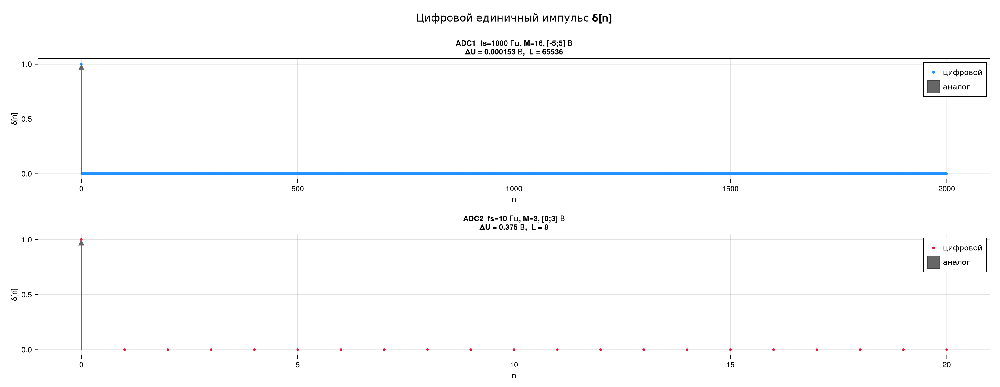

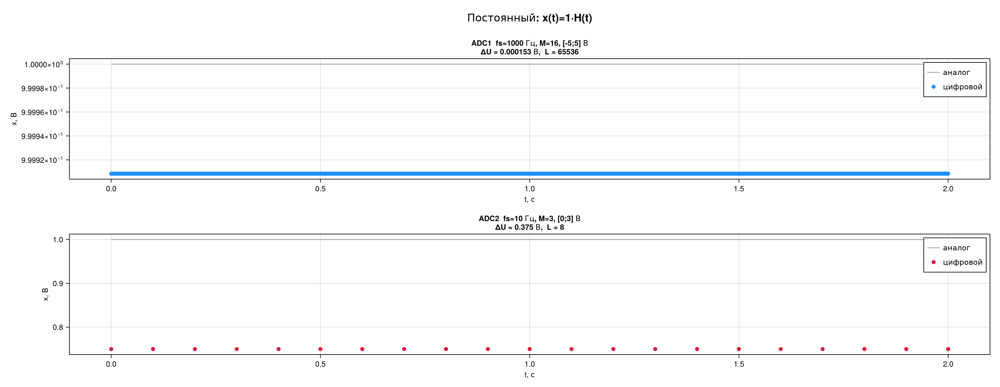

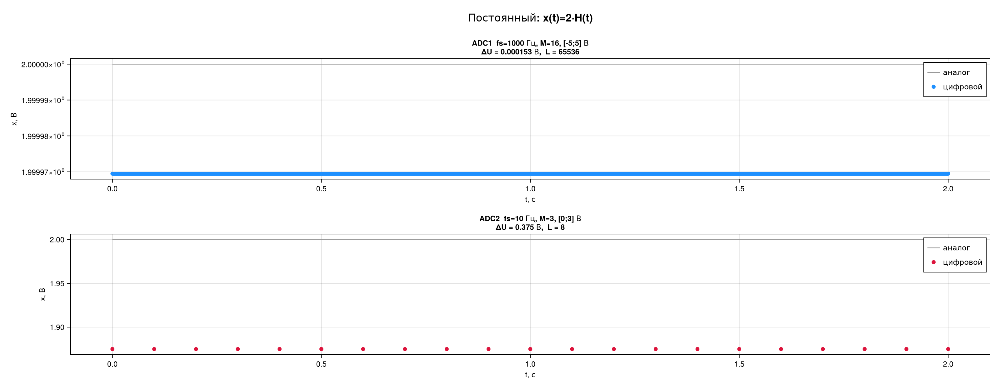

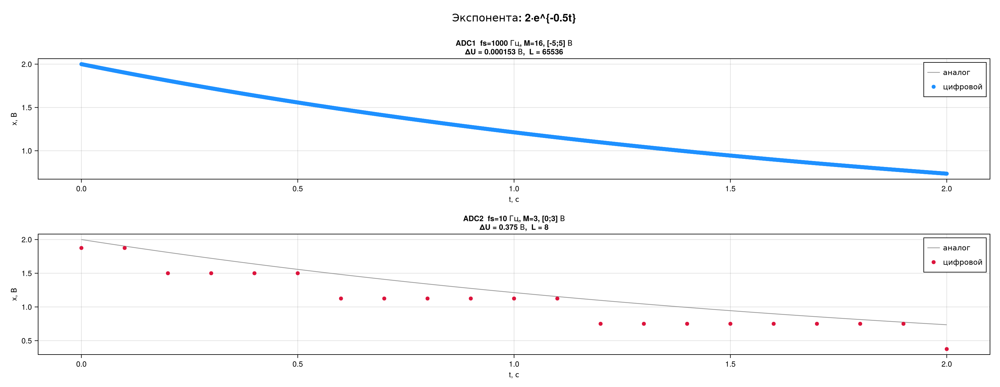

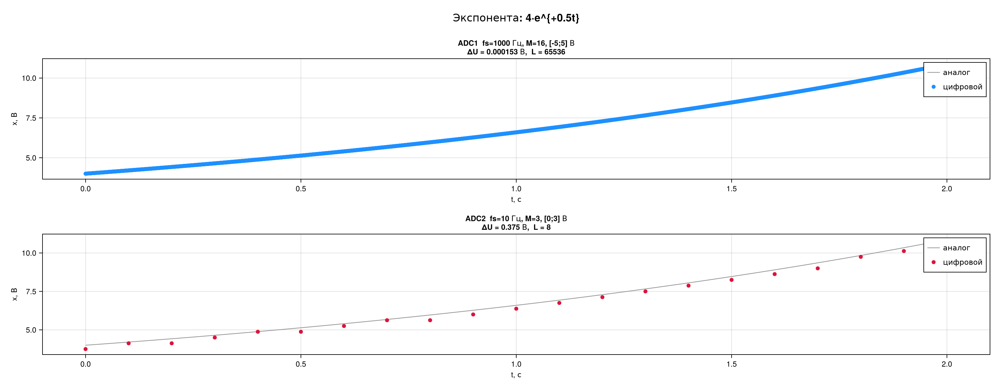

...

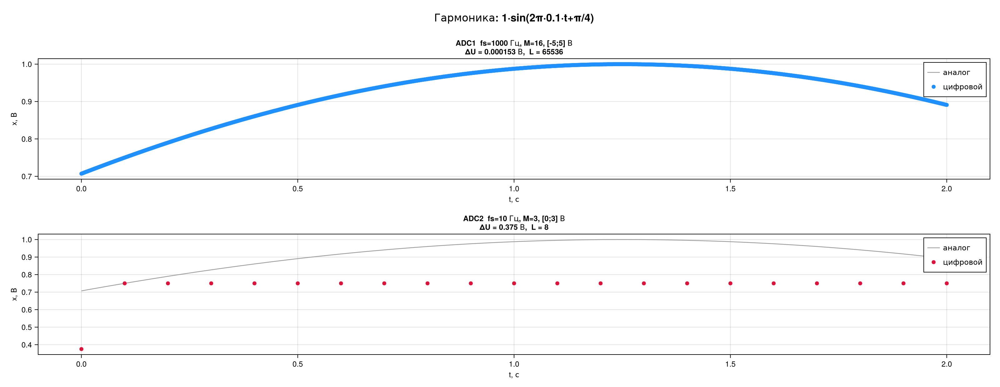

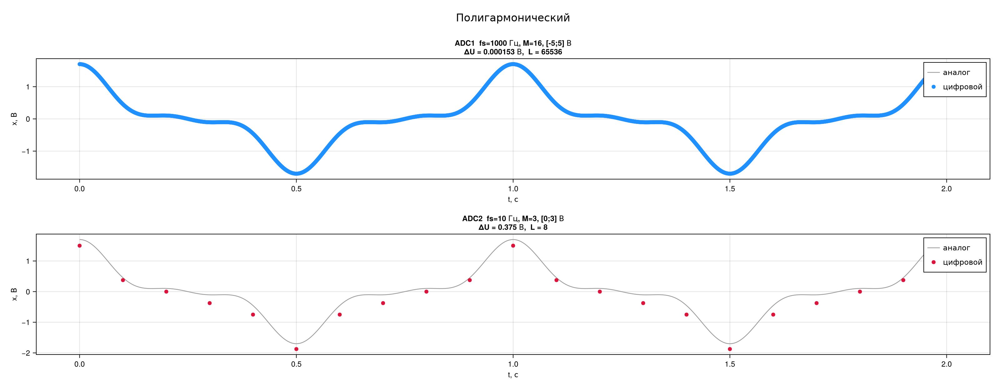

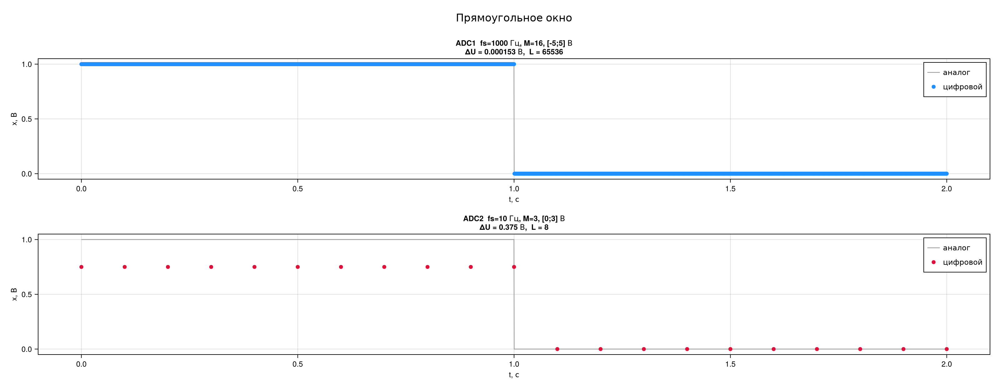

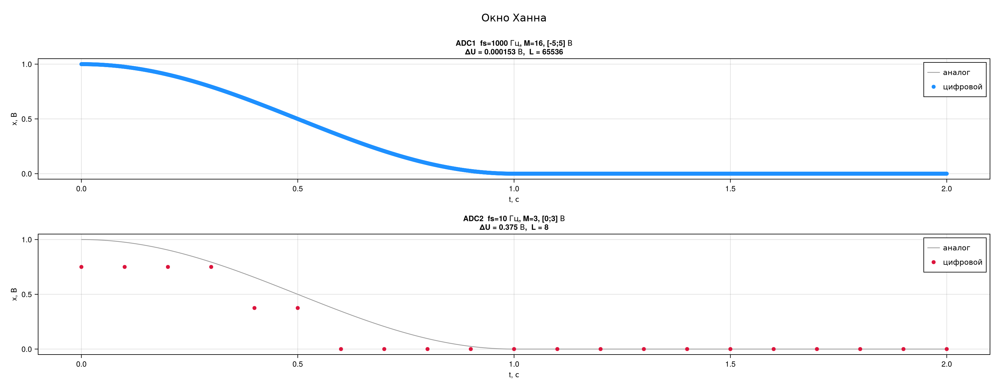

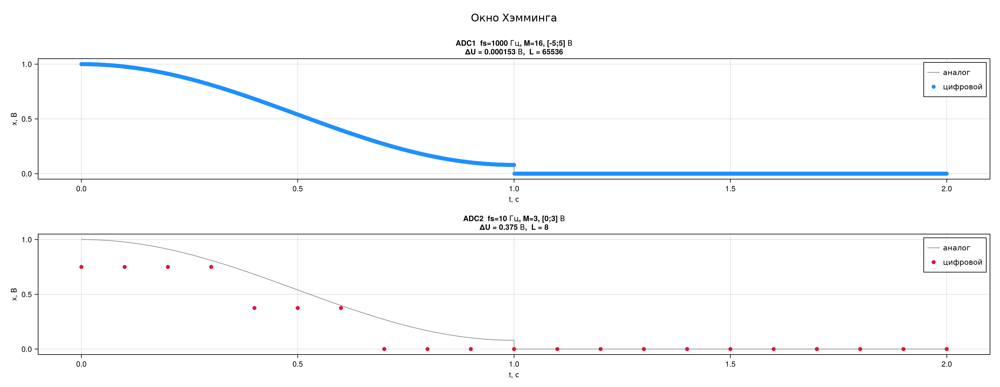

In [12]:
using CairoMakie

# ---------- Функция Хевисайда (единичный скачок) ----------
# H(t) = 0 при t < 0,  H(0) = 1,  H(t) = 1 при t > 0   (правая непрерывная конвенция)
H(τ) = τ < 0 ? 0.0 : 1.0
H(τ::AbstractArray) = ifelse.(τ .< 0, 0.0, 1.0)

function adc(x, Umin, Umax, M)
    L  = 2^M
    ΔU = (Umax - Umin) / L
    xD = floor.(Int, (x .- Umin) ./ (Umax - Umin) .* L)
    xD_clamped = clamp.(xD, 0, L - 1)
    xq = xD .* ΔU .+ Umin
    xq_clamped = clamp.(xq, Umin, Umax - ΔU)
    return xD, xq, xD_clamped, xq_clamped, ΔU, L
end

adcs = [
    (name="ADC1  fs=1000 Гц, M=16, [-5;5] В",
     fs=1000, M=16, Umin=-5.0, Umax=5.0, col=:dodgerblue),
    (name="ADC2  fs=10 Гц, M=3, [0;3] В",
     fs=10,   M=3,  Umin= 0.0, Umax=3.0, col=:crimson),
]
Tmax = 2.0

# ---------- Формирование текстового вывода кодов xD ----------
function codes_string(signal_name, adcVar, xD; maxshow=10)
    L  = 2^adcVar.M
    ΔU = (adcVar.Umax - adcVar.Umin) / L
    io = IOBuffer()
    println(io, "="^74)
    println(io, "Сигнал   : ", signal_name)
    println(io, "АЦП      : ", adcVar.name)
    println(io, "Параметры: M = $(adcVar.M),  L = $L,  ΔU = $(round(ΔU, digits=8)) В,  ",
                 "диапазон [$(adcVar.Umin); $(adcVar.Umax)] В")
    N = length(xD)
    if N <= 2 * maxshow
        for (i, c) in enumerate(xD)
            println(io, "  xD[$(i-1)] = ", c)
        end
    else
        for i in 1:maxshow
            println(io, "  xD[$(i-1)] = ", xD[i])
        end
        println(io, "  ...   (пропущено $(N - 2*maxshow) значений) ...")
        for i in (N - maxshow + 1):N
            println(io, "  xD[$(i-1)] = ", xD[i])
        end
    end
    println(io, "  Всего отсчётов: ", N)
    return String(take!(io))
end

# ---------- Универсальный рисователь ----------
# Возвращает (fig, texts), где texts — вектор строк для вывода до рисунка.
function render(name, fun; tmax=Tmax)
    fig = Figure(size=(1600, 620), fontsize=12)
    Label(fig[0, 1], name, fontsize=17, font=:bold, tellwidth=false)

    t_fine = range(0, tmax, length=4000)
    texts  = String[]

    for (j, adcVar) in enumerate(adcs)
        Ts = 1 / adcVar.fs
        n  = 0:round(Int, tmax / Ts)
        tn = n .* Ts
        xa = fun(tn)
        xD, xq, _, _, ΔU, L = adc(xa, adcVar.Umin, adcVar.Umax, adcVar.M)

        push!(texts, codes_string(name, adcVar, xD))

        ax = Axis(fig[j, 1],
            title = "$(adcVar.name)\nΔU = $(round(ΔU, digits=6)) В,  L = $L",
            xlabel = "t, с", ylabel = "x, В")

        lines!(ax, t_fine, fun(t_fine), color=:gray60, linewidth=1.2, label="аналог")
        scatter!(ax, tn, xq, color=adcVar.col, markersize=9, label="цифровой")
        axislegend(ax, position=:rt)
    end

    rowsize!(fig.layout, 0, Fixed(30))
    rowsize!(fig.layout, 1, Relative(0.47))
    rowsize!(fig.layout, 2, Relative(0.47))
    colsize!(fig.layout, 1, Relative(1.0))

    return fig, texts
end

# Постоянный сигнал x(t) = a_i * H(t):  на интервале моделирования t ∈ [0; Tmax] Хевисайд
# равен 1 во всех точках, поэтому цифровой сигнал — постоянная величина a_i (см. отчёт).
consts = [("Постоянный: x(t)=1·H(t)", t -> 1.0 .* H(t)),
          ("Постоянный: x(t)=2·H(t)", t -> 2.0 .* H(t))]

exps = [("Экспонента: 2·e^{-0.5t}", t->2 .* exp.(-0.5 .* t)),
        ("Экспонента: 4·e^{+0.5t}", t->4 .* exp.( 0.5 .* t))]

harms = [("Гармоника: 0.5·sin(2π·1·t)",     t->0.5 .* sin.(2π .* 1   .* t)),
         ("Гармоника: 5·sin(2π·100·t)",     t->5.0 .* sin.(2π .* 100 .* t)),
         ("Гармоника: 1·sin(2π·0.1·t+π/4)", t->1.0 .* sin.(2π .* 0.1 .* t .+ π/4))]

poly = t -> cos.(2π .* t) .+ 0.5 .* cos.(2π .* 3 .* t) .+ 0.2 .* cos.(2π .* 5 .* t)

windows = [("Прямоугольное окно", t -> (abs.(t) .<= Tmax/2) .* 1.0),
        ("Окно Ханна",         t -> 0.5 .* (1 .+ cos.(2π .* t ./ Tmax)) .* (abs.(t) .<= Tmax/2)),
        ("Окно Хэмминга",      t -> (0.54 .+ 0.46 .* cos.(2π .* t ./ Tmax)) .* (abs.(t) .<= Tmax/2))]


all_texts = String[]
all_figs  = Any[] 

# ---------- δ-импульс (дискретный δ[n]) ----------
let
    fig_δ = Figure(size=(1600, 620), fontsize=12)
    Label(fig_δ[0, 1], "Цифровой единичный импульс δ[n]", fontsize=17, font=:bold,
          tellwidth=false)

    for (j, adcVar) in enumerate(adcs)
        N = round(Int, Tmax * adcVar.fs)
        n = 0:N
        delta = Float64.(n .== 0)

        xD, xq, _, _, ΔU, L = adc(delta, adcVar.Umin, adcVar.Umax, adcVar.M)

        push!(all_texts, codes_string("δ[n]", adcVar, xD))

        ax = Axis(fig_δ[j, 1],
            title = "$(adcVar.name)\nΔU = $(round(ΔU, digits=6)) В,  L = $L",
            xlabel = "n", ylabel = "δ[n]")

        scatter!(ax, n, delta; color = adcVar.col, markersize = 6, label = "цифровой")

        arrows!(ax, [0.0], [0.0], [0.0], [1.0],
                color = :gray40, linewidth = 2, arrowsize = 12, label = "аналог")

        axislegend(ax, position = :rt)
    end

    rowsize!(fig_δ.layout, 0, Fixed(30))
    rowsize!(fig_δ.layout, 1, Relative(0.47))
    rowsize!(fig_δ.layout, 2, Relative(0.47))
    colsize!(fig_δ.layout, 1, Relative(1.0))

    push!(all_figs, fig_δ)
end

# ---------- Остальные сигналы ----------
for (name, fun) in vcat(consts, exps, harms, [("Полигармонический", poly)], windows)
    fig, texts = render(name, fun)
    append!(all_texts, texts)
    push!(all_figs, fig)
end

for s in all_texts
    println(stdout, s)
end
flush(stdout)

for fig in all_figs
    display(fig)
end

### 1.2. Определение параметров АЦП

---
``Задание``
1. Определить количество уровней квантования и шаг квантования АЦП.

2. Построить график характеристики АЦП следующим образом:
* Построить график функции:
$$x(t)= t, \space t  = -1 : 0.01 : 4 $$
* Применить уравнения квантования ``(1*, 2)`` к каждой точке $x(t)$ и вывести получившиеся значения $x_q(t)$ на тот же график.
* Отобразить уровни квантования на том же графике
На основании полученной характеристики преобразования АЦП определить шум квантования (значение ошибки квантования) и построть его график:  
$$e_q(t)=x(t)-x_q(n),$$
---




ADC1  fs=1000 Гц, M=16, [-5;5] В
Количество уровней L = 2^M = 65536
Шаг квантования ΔU = (Umax - Umin)/L = 0.0001525879 В
Диапазон: [-5.0; 5.0] В
e_q (1*):     min = 0.0, max = 0.000151
e_q (2):  min = 0.0, max = 0.000151
ADC2  fs=10 Гц, M=3, [0;3] В
Количество уровней L = 2^M = 8
Шаг квантования ΔU = (Umax - Umin)/L = 0.375 В
Диапазон: [0.0; 3.0] В
e_q (1*):     min = -1.0, max = 1.375
e_q (2):  min = 0.0, max = 0.37


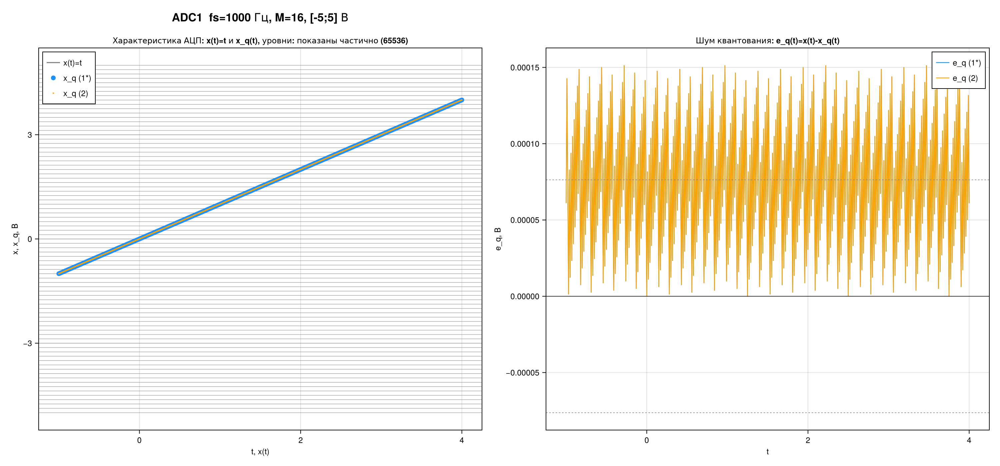

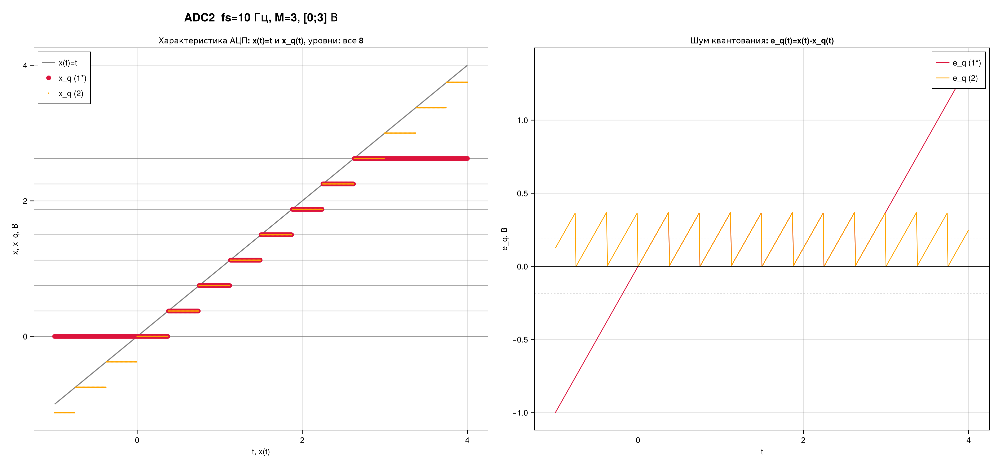

In [13]:
function plot_adc_characteristic(adcVar; max_levels=80)
    # x(t) = t, t = -1 : 0.01 : 4
    t = collect(-1.0:0.01:4.0)
    x = t

    xD, xq, xD_clamped, xq_clamped, ΔU, L =
        adc(x, adcVar.Umin, adcVar.Umax, adcVar.M)

    xq_eq1 = xq_clamped
    xq_eq2 = xq

    eq1 = x .- xq_eq1
    eq2 = x .- xq_eq2

    println("="^70)
    println(adcVar.name)
    println("Количество уровней L = 2^M = $L")
    println("Шаг квантования ΔU = (Umax - Umin)/L = $(round(ΔU, digits=10)) В")
    println("Диапазон: [$(adcVar.Umin); $(adcVar.Umax)] В")
    println("e_q (1*):     min = $(round(minimum(eq1), digits=6)), max = $(round(maximum(eq1), digits=6))")
    println("e_q (2):  min = $(round(minimum(eq2), digits=6)), max = $(round(maximum(eq2), digits=6))")

    fig = Figure(size=(1500, 700), fontsize=12)
    Label(fig[0, 1], "$(adcVar.name)", fontsize=17, font=:bold, tellwidth=false)

    level_note = L <= max_levels ? "уровни: все $L" : "уровни: показаны частично ($L)"

    ax1 = Axis(fig[1, 1],
        title = "Характеристика АЦП: x(t)=t и x_q(t), $level_note",
        xlabel = "t, x(t)", ylabel = "x, x_q, В")

    lines!(ax1, t, x, color=:gray50, linewidth=1.6, label="x(t)=t")

    # Уровни квантования
    levels = adcVar.Umin .+ (0:L-1) .* ΔU
    if L <= max_levels
        hlines!(ax1, levels, color=:gray, linewidth=0.7)
    else
        step = max(1, L ÷ max_levels)
        hlines!(ax1, levels[1:step:end], color=:gray, linewidth=0.5)
    end

    scatter!(ax1, t, xq_eq1,
        color=adcVar.col, markersize=10,
        label="x_q (1*)")
    scatter!(ax1, t, xq_eq2,
        color=:orange, markersize=3,
        label="x_q (2)")

    axislegend(ax1, position=:lt)

    ax2 = Axis(fig[1, 2],
        title = "Шум квантования: e_q(t)=x(t)-x_q(t)",
        xlabel = "t", ylabel = "e_q, В")

    lines!(ax2, t, eq1, color=adcVar.col, linewidth=1.2,
        label="e_q (1*)")
    lines!(ax2, t, eq2, color=:orange, linewidth=1.2,
        label="e_q (2)")

    hlines!(ax2, 0.0, color=:black, linewidth=0.8)
    hlines!(ax2, [ΔU/2, -ΔU/2], color=:gray, linewidth=0.8, linestyle=:dash)

    axislegend(ax2, position=:rt)

    display(fig)
end

for adcVar in adcs
    plot_adc_characteristic(adcVar)
end

### 2 Неделя (17.09.26 - 24.09.26)

### 2.1. Свертка и корреляция

Даны следующие функции:
 1. Прямоугольное окно

$$x_1(t) = \begin{cases}
1, & 0 \le t \le 2 \\
0, & \text{else}
\end{cases}$$


2. Треугольное окно

$$x_2(t) = \begin{cases}
t, & 0 \le t < 1 \\
2 - t, & 1 \le t \le 2 \\
0, & \text{else}
\end{cases}$$

3. Синусоидальный сигнал

$$x_3(t) = \begin{cases}
\sin(2\pi t), & 0 \le t \le 2 \\
0, & \text{else}
\end{cases}$$

---
``Задание``
1. Проведите дискретизацию функций $x_1(t), x_2(t), x_3(t)$ с частотой $Fs = 1000$, временем моделирования $n \in [-4000,4000]$ и получите соответствующие дискретные функции $x_1[n],x_2[n],x_3[n]$.
2. Реализуйте формулы дискретной свёртки и корреляции с помощью базовых средств языка Julia.
3. Вычислите свёртку и постройте график для следующих функций:
    * $x_1[n] * x_2[n]$
    * $x_1[n] * x_3[n]$
    * $x_2[n] * x_3[n]$
    * $x_1[n] * x_1[n]$
    * $x_3[n] * x_3[n]$
4. Вычислите корреляцию и постройте график для следующих функций:
    * $x_1[n] \star x_2[n]$
    * $x_3[n] \star x_3[n]$
5. Скачайте файлы ``signal_1.csv`` и ``signal_2.csv``. Постройте графики сигналов. Вычислите корреляцию, постройте график. Какой вывод можно сделать по полученным результатам? Где находится максимум корреляционной функции?
---

1. ДИСКРЕТИЗАЦИЯ (Fs = 1000 Гц, n ∈ [-4000, 4000])
   Всего отсчётов t: 8001
   x1[n] — ненулевых: 2001
   x2[n] — ненулевых: 1999
   x3[n] — ненулевых: 2000

2. СВЁРТКИ
   x1 * x2 : длина = 16001, max(|·|) = 1000.0 при t = 1.999 с
   x1 * x3 : длина = 16001, max(|·|) = 318.3088 при t = 0.499 с
   x2 * x3 : длина = 16001, max(|·|) = -159.1544 при t = 3.001 с
   x1 * x1 : длина = 16001, max(|·|) = 2001.0 при t = 2.0 с
   x3 * x3 : длина = 16001, max(|·|) = -1000.0 при t = 2.0 с

3. КОРРЕЛЯЦИИ
   x1 ⋆ x2 : максимум R = 1000.0 при lag = -1 отсчётов (τ = -0.001 с)
   x3 ⋆ x3 : максимум R = 1000.0 при lag = 0 отсчётов (τ = 0.0 с)

4. АНАЛИЗ CSV-ФАЙЛОВ
   signal_1.csv : 315904 отсчётов, min = -40.9851, max = 35.9497
   signal_2.csv : 41984 отсчётов, min = -40.5579, max = 35.614
   Взаимная корреляция signal_1 ⋆ signal_2:
     максимум РКФ: R = 438618.193 при lag = 50688 отсчётов (τ = 50.688 с)
     => максимум не при lag = 0: сигналы не синхронны; signal_2[n] ≈ signal_1[n + 50688],
        т

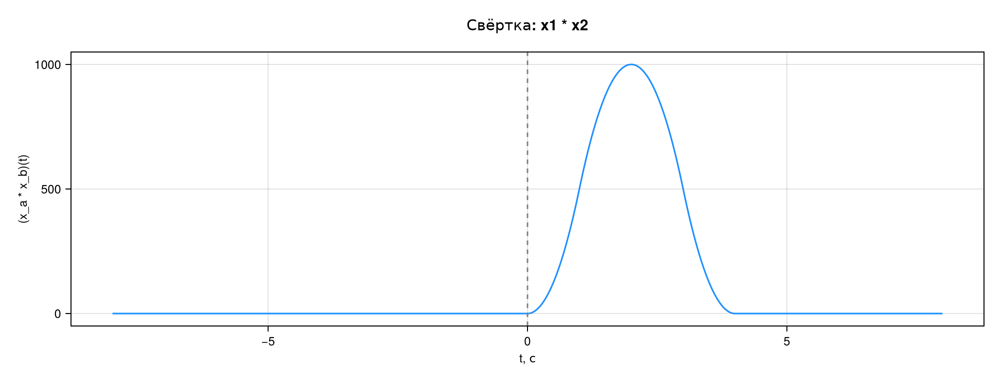

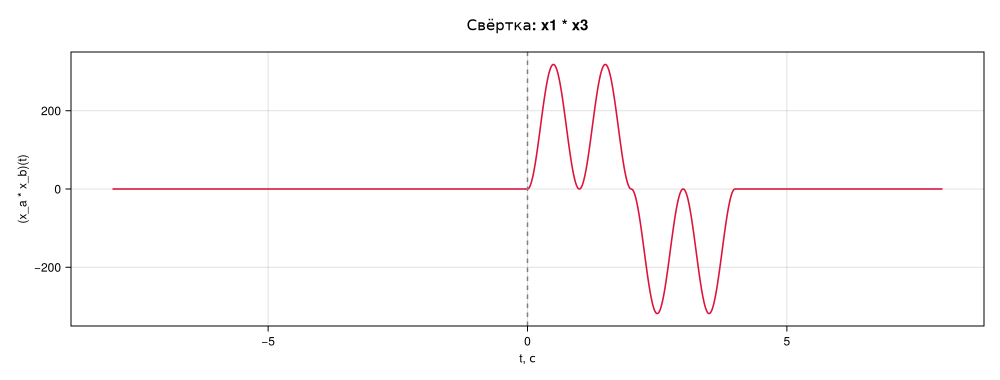

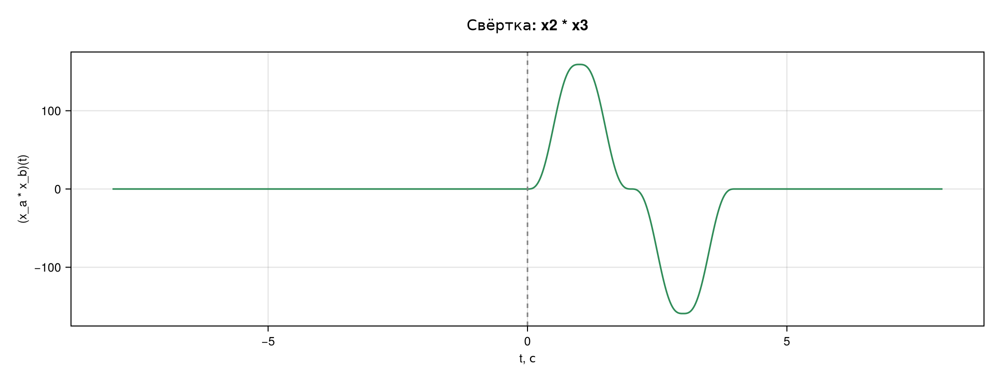

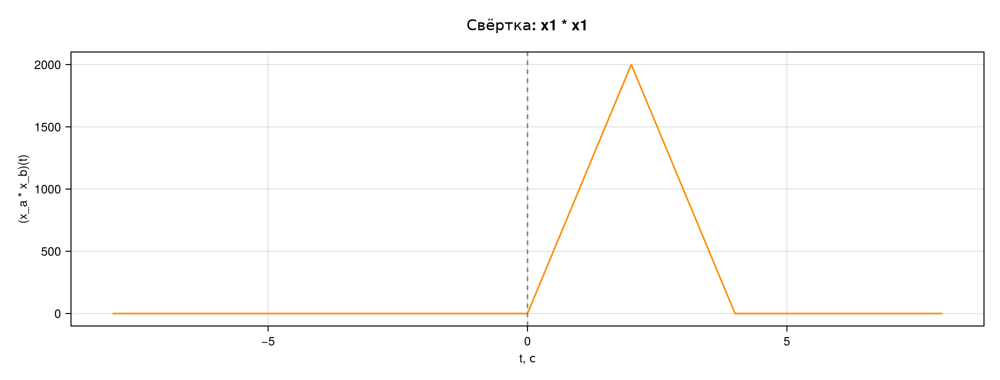

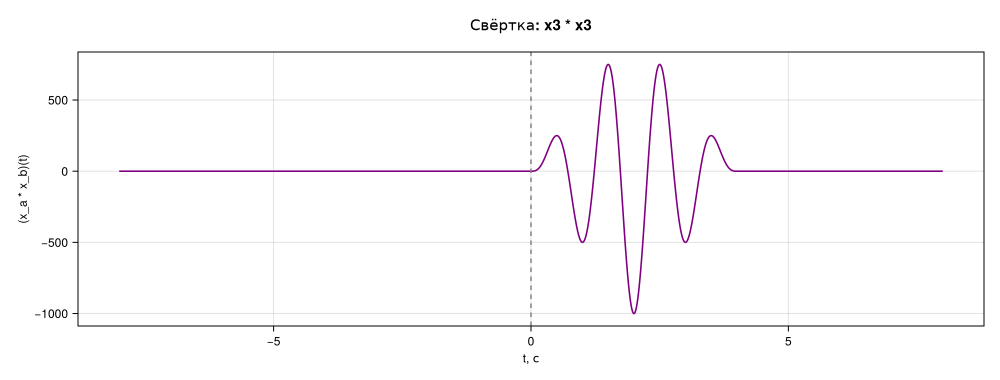

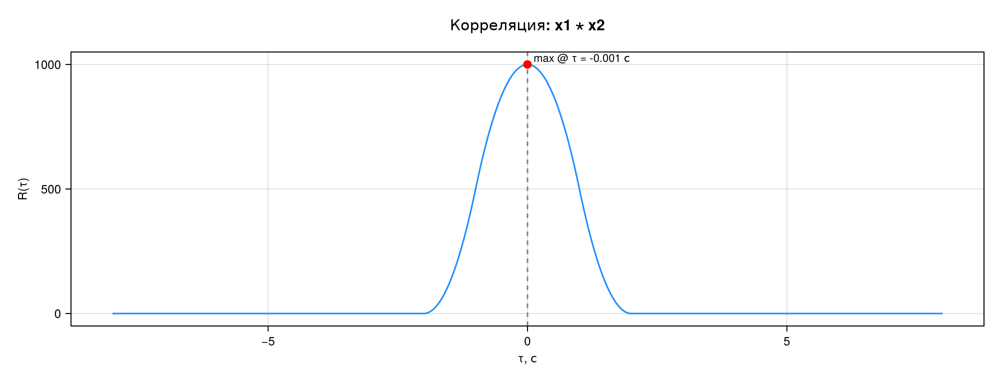

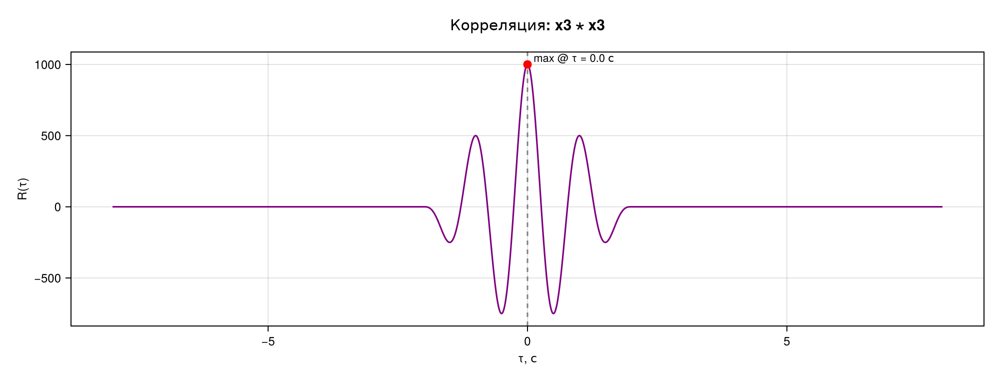

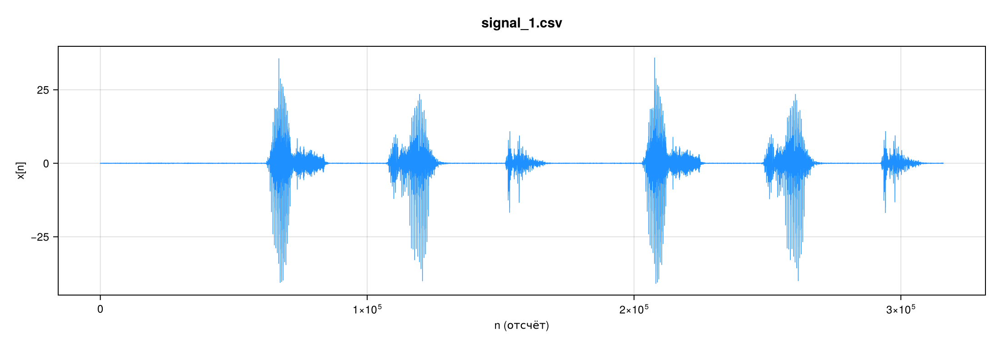

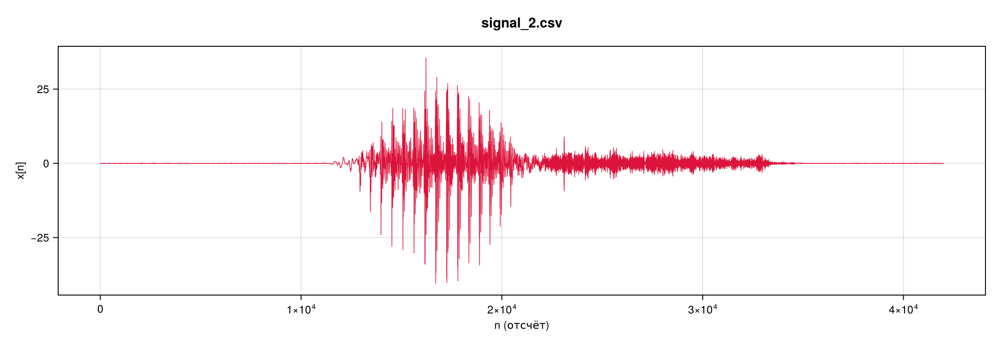

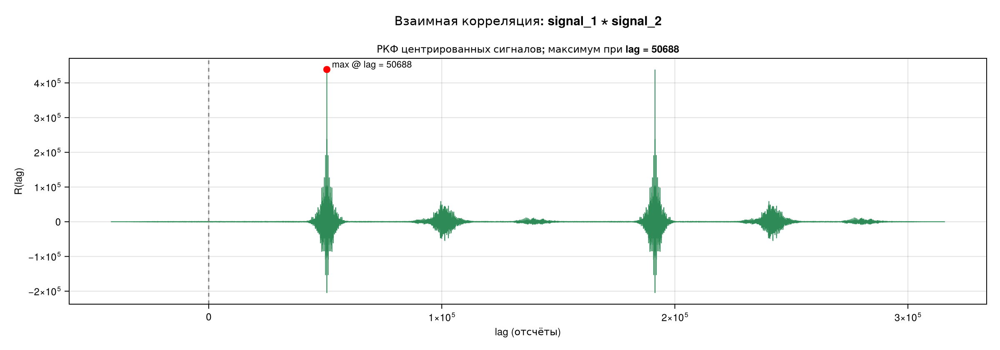

CairoMakie.Screen{IMAGE}


In [14]:
using CairoMakie
using DelimitedFiles
using LinearAlgebra

# 1. Дискретизация x1, x2, x3
Fs = 1000
n_range = -4000:4000
t = collect(n_range) ./ Fs         # вектор времени t = n/Fs, t ∈ [-4, 4]

x1f(τ) = (0.0 <= τ <= 2.0) ? 1.0 : 0.0
x2f(τ) = (0.0 <= τ < 1.0) ? τ :
         ((1.0 <= τ <= 2.0) ? (2.0 - τ) : 0.0)
x3f(τ) = (0.0 <= τ <= 2.0) ? sin(2π * τ) : 0.0

x1n = [x1f(ti) for ti in t]
x2n = [x2f(ti) for ti in t]
x3n = [x3f(ti) for ti in t]

println("="^72)
println("1. ДИСКРЕТИЗАЦИЯ (Fs = $Fs Гц, n ∈ [-4000, 4000])")
println("   Всего отсчётов t: $(length(t))")
println("   x1[n] — ненулевых: $(count(!=(0.0), x1n))")
println("   x2[n] — ненулевых: $(count(!=(0.0), x2n))")
println("   x3[n] — ненулевых: $(count(!=(0.0), x3n))")
println("="^72)

# 2. Свёртка и корреляция
function dconv(x, y)
    Nx, Ny = length(x), length(y)
    out = zeros(Float64, Nx + Ny - 1)
    @inbounds for i in 1:Nx
        xi = x[i]
        xi == 0.0 && continue
        for j in 1:Ny
            yj = y[j]
            yj == 0.0 && continue
            out[i + j - 1] += xi * yj
        end
    end
    return out
end

function dcorr(x, y)
    Nx, Ny = length(x), length(y)
    lags = collect(-(Ny - 1):(Nx - 1))
    out  = zeros(Float64, length(lags))
    @inbounds for (idx, m) in enumerate(lags)
        s = 0.0
        for k in 1:Nx
            j = k - m
            if 1 <= j <= Ny
                s += x[k] * y[j]
            end
        end
        out[idx] = s
    end
    return out, lags
end

# 3. Свёртки
println("\n2. СВЁРТКИ")
conv_pairs = [
    ("x1 * x2", x1n, x2n, :dodgerblue),
    ("x1 * x3", x1n, x3n, :crimson),
    ("x2 * x3", x2n, x3n, :seagreen),
    ("x1 * x1", x1n, x1n, :darkorange),
    ("x3 * x3", x3n, x3n, :purple),
]

m_start = 2 * n_range[1]
m_end   = 2 * n_range[end]
m_range = collect(m_start:m_end)
tc = m_range ./ Fs                 # ось времени для свёртки

for (name, xa, xb, col) in conv_pairs
    yc = dconv(xa, xb)
    imax = argmax(abs.(yc))
    println("   $name : длина = $(length(yc)), " *
            "max(|·|) = $(round(yc[imax], digits=4)) при t = $(round(tc[imax], digits=4)) с")

    fig = Figure(size=(1000, 380), fontsize=12)
    Label(fig[0, 1], "Свёртка: $name", fontsize=15, font=:bold, tellwidth=false)
    ax = Axis(fig[1, 1], xlabel="t, с", ylabel="(x_a * x_b)(t)")
    lines!(ax, tc, yc, color=col, linewidth=1.6)
    vlines!(ax, 0.0, color=:gray, linestyle=:dash)
    display(fig)
end

# 4. Корреляции
println("\n3. КОРРЕЛЯЦИИ")
corr_pairs = [
    ("x1 ⋆ x2", x1n, x2n, :dodgerblue),
    ("x3 ⋆ x3", x3n, x3n, :purple),
]

for (name, xa, xb, col) in corr_pairs
    R, lags = dcorr(xa, xb)
    tlag = lags ./ Fs
    imax = argmax(R)
    println("   $name : максимум R = $(round(R[imax], digits=4)) " *
            "при lag = $(lags[imax]) отсчётов (τ = $(round(tlag[imax], digits=4)) с)")

    fig = Figure(size=(1000, 380), fontsize=12)
    Label(fig[0, 1], "Корреляция: $name", fontsize=15, font=:bold, tellwidth=false)
    ax = Axis(fig[1, 1], xlabel="τ, с", ylabel="R(τ)")
    lines!(ax, tlag, R, color=col, linewidth=1.6)
    vlines!(ax, 0.0, color=:gray, linestyle=:dash)
    scatter!(ax, [tlag[imax]], [R[imax]], color=:red, markersize=12)
    text!(ax, tlag[imax], R[imax],
          text="  max @ τ = $(round(tlag[imax], digits=4)) с",
          align=(:left, :bottom), fontsize=11)
    display(fig)
end

# 5. Загрузка CSV, графики и корреляция
println("\n4. АНАЛИЗ CSV-ФАЙЛОВ")

function load_signal(path)
    if !isfile(path)
        @warn "Файл $path не найден — пропускаем"
        return nothing
    end
    data = readdlm(path, Float64)
    return vec(data)
end

sig1 = load_signal("signal_1.csv")
sig2 = load_signal("signal_2.csv")

# ---- График signal_1 ----
if sig1 !== nothing
    println("   signal_1.csv : $(length(sig1)) отсчётов, " *
            "min = $(round(minimum(sig1), digits=4)), " *
            "max = $(round(maximum(sig1), digits=4))")
    fig = Figure(size=(1100, 380), fontsize=12)
    Label(fig[0, 1], "signal_1.csv", fontsize=15, font=:bold, tellwidth=false)
    ax = Axis(fig[1, 1], xlabel="n (отсчёт)", ylabel="x[n]")
    lines!(ax, 1:length(sig1), sig1, color=:dodgerblue, linewidth=0.7)
    display(fig)
end

# ---- График signal_2 ----
if sig2 !== nothing
    println("   signal_2.csv : $(length(sig2)) отсчётов, " *
            "min = $(round(minimum(sig2), digits=4)), " *
            "max = $(round(maximum(sig2), digits=4))")
    fig = Figure(size=(1100, 380), fontsize=12)
    Label(fig[0, 1], "signal_2.csv", fontsize=15, font=:bold, tellwidth=false)
    ax = Axis(fig[1, 1], xlabel="n (отсчёт)", ylabel="x[n]")
    lines!(ax, 1:length(sig2), sig2, color=:crimson, linewidth=0.7)
    display(fig)
end

# ---- Взаимная корреляция ----
# Формула та же, что в dcorr(): R[m] = Σ_k x[k]·y[k−m], но каждое R[m] считается одним
# скалярным произведением (dot → BLAS) — для 3·10^5 и 4·10^4 отсчётов прямая реализация
# «в лоб» неприемлема. Сигналы сопоставляются целиком, без обрезания по длине.
function xcorr(x, y)
    Nx, Ny = length(x), length(y)
    R = zeros(Float64, Nx + Ny - 1)
    @inbounds for m in -(Ny - 1):(Nx - 1)
        i0 = max(1, 1 + m)
        j0 = max(1, 1 - m)
        n  = min(Nx - i0 + 1, Ny - j0 + 1)
        R[m + Ny] = dot(view(x, i0:i0 + n - 1), view(y, j0:j0 + n - 1))
    end
    return R, collect(-(Ny - 1):(Nx - 1))
end

if sig1 !== nothing && sig2 !== nothing
    N1, N2 = length(sig1), length(sig2)
    # Центрируем (убираем постоянную составляющую) — так корреляция информативнее
    s1c = sig1 .- sum(sig1) / N1
    s2c = sig2 .- sum(sig2) / N2

    R, lags = xcorr(s1c, s2c)
    imax = argmax(R)
    τmax = lags[imax]

    println("   Взаимная корреляция signal_1 ⋆ signal_2:")
    println("     максимум РКФ: R = $(round(R[imax], digits=3)) при lag = $τmax отсчётов " *
            "(τ = $(round(τmax / Fs, digits=4)) с)")
    println("     => максимум не при lag = 0: сигналы не синхронны; signal_2[n] ≈ signal_1[n + $τmax],")
    println("        т.е. второй сигнал — это отрезок первого, сдвинутый на $τmax отсчётов")

    fig = Figure(size=(1200, 420), fontsize=12)
    Label(fig[0, 1], "Взаимная корреляция: signal_1 ⋆ signal_2",
          fontsize=15, font=:bold, tellwidth=false)
    ax = Axis(fig[1, 1], xlabel = "lag (отсчёты)", ylabel = "R(lag)",
              title = "РКФ центрированных сигналов; максимум при lag = $τmax")
    lines!(ax, lags, R, color=:seagreen, linewidth=1.0)
    vlines!(ax, 0.0, color=:gray, linestyle=:dash)
    scatter!(ax, [τmax], [R[imax]], color=:red, markersize=12)
    text!(ax, τmax, R[imax], text = "  max @ lag = $τmax",
          align=(:left, :bottom), fontsize=11)
    display(fig)
end


### 2.2. Дискретные LTI-системы

Даны следующие дискретные системы:
1. $F_1:\space y_1(n) = x(n)$
2. $F_2:\space y_2(n) =  \sum_{i=0}^{5} \frac{1}{5} * x(n-i)  $
3. $ F_3:\space  y_3(n) = -\frac{1}{4}x(n)$
4. $F_4:\space y_4(n) = x(n-4)$
5. $F_5:\space  y_5(n) = 2y(n-1)+x(n)$
6. $F_6:\space  y_6(n) = \frac{1}{2}|x(n)|$
7. $F_7:\space  y_7(n) = \sum_{i=0}^{31}b_i x(n-i),\ $ <small> $b = [-0.026, -0.6, -0.017, -0.01, -0.022, -0.015, -0.03, -0.023, -0.041, -0.036, -0.059, -0.059, -0.094, -0.117, -0.218, -0.629, 0.629, 0.218, 0.117, 0.094, 0.059, 0.059, 0.036, 0.041, 0.023, 0.03, 0.015, 0.022, 0.01, 0.017, 0.6, 0.026]$ </small>

8. $F_8:\space y_8 = \sum_{i=0}^{5} b_i x(n-i) - \sum_{i=1}^{5} a_i y(n-i)$
    <small> $b = [0.0646,  -0.1235,    0.1949,   -0.1949,    0.1235,   -0.0646]$ </small><small> $a = [1.0000 + 0.0000i,   1.4576 - 0.1880i,   2.3598 - 0.2122i,   1.8195 - 0.1694i,   1.0772 - 0.0556i,   0.3218 + 0.0000i]$ </small>  

9. $F_8:\space y_8 = \sum_{i=0}^{5} b_i x(n-i) - \sum_{i=1}^{5} a_i y(n-i)$
    <small> $b = [0.0646,   -0.1235,    0.1949,   -0.1949,    0.1235,   -0.0646]$ </small><small> $a = [1.0000,    1.4277,    2.1448,    1.5880,    0.9051,    0.2682]$ </small>

Время моделирования для систем:  
 $ F_1 - F_4, F_6$: $N_{max}=15$ отсчетов  
 $ F_7 - F_9, F_5$: $N_{max}=40$ отсчетов  

---
``Задание``
1. Определите какие системы являются линейными.
2. Определите какие системы обладают свойство инвариантности во времени.
3. Для каждой системы вычислите импульсную характеристику и постройте её график. Для каких систем вычисление импульсной характеристики имеет практический смысл?
4. Какие системы являются устойчивыми, а какие нет?
5. Подать в качестве входного сигнала для систем $F_2$ и $F_7$ следующие:

$$ x_1(n) =\sin(2\pi \cdot 0.01 \cdot n)  $$

$$ x_2(n) =  \sin(2\pi \cdot 0.2 \cdot n) $$
Проанализировать полученные результаты. Какие характеристики входного сигнала изменились?

6. Воспользовавшись графическим интерфейсом моделирования в Engee реализуйте системы $F_2$ и $F_5$ c помощью блоков сложения, умножения и запаздывания. Подайте в качестве входного сигнала единичный дискретный импульс и выведите выходной сигнал на осциллограф. Сравните результаты с полученными ранее.

---


п.1–2  Линейность и инвариантность во времени:
  F1   линейна=да      ТИВ=да
  F2   линейна=да      ТИВ=да
  F3   линейна=да      ТИВ=да
  F4   линейна=да      ТИВ=да
  F5   линейна=да      ТИВ=да
  F6   линейна=НЕТ     ТИВ=да
  F7   линейна=да      ТИВ=да
  F8   линейна=да      ТИВ=да
  F9   линейна=да      ТИВ=да
  F6 нелинейна: |a·x1 + b·x2|/2 ≠ a|x1|/2 + b|x2|/2;  ТИВ выполняется (система без памяти)

п.3  Импульсные характеристики h[n] = T{δ[n]}:
  h[F1](0..5) = [1.0, 0.0, 0.0, 0.0, 0.0, 0.0]
  h[F2](0..5) = [0.2, 0.2, 0.2, 0.2, 0.2, 0.2]
  h[F3](0..5) = [-0.25, 0.0, 0.0, 0.0, 0.0, 0.0]
  h[F4](0..5) = [0.0, 0.0, 0.0, 0.0, 1.0, 0.0]
  h[F5](0..5) = [1.0, 2.0, 4.0, 8.0, 16.0, 32.0]
  h[F6](0..5) = [0.5, 0.0, 0.0, 0.0, 0.0, 0.0]
  h[F7](0..5) = [-0.026, -0.6, -0.017, -0.01, -0.022, -0.015]
  h[F8](0..5) = [0.0646, -0.2177, 0.3574, -0.3139, 0.0586, 0.1526]
  h[F9](0..5) = [0.0646, -0.2157, 0.3643, -0.355, 0.1329, 0.1063]

п.4  Устойчивость:
  F5: max|z| = 2.0  =>  не устойчива   (|h

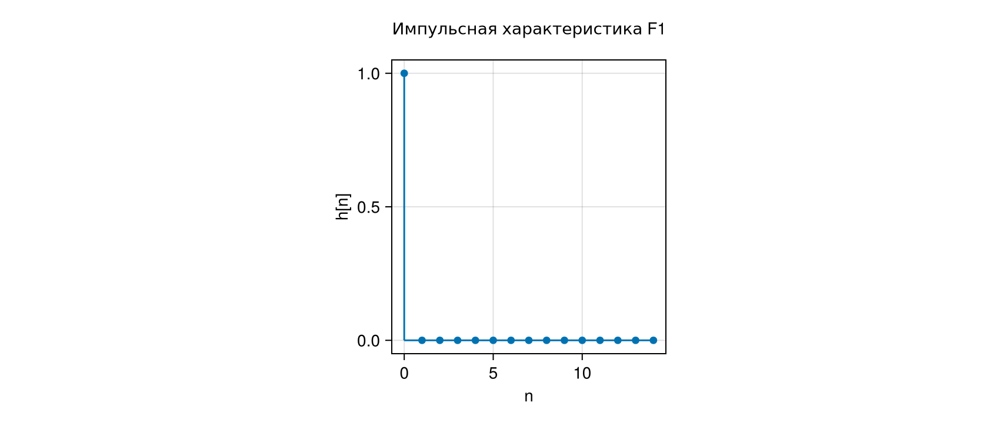

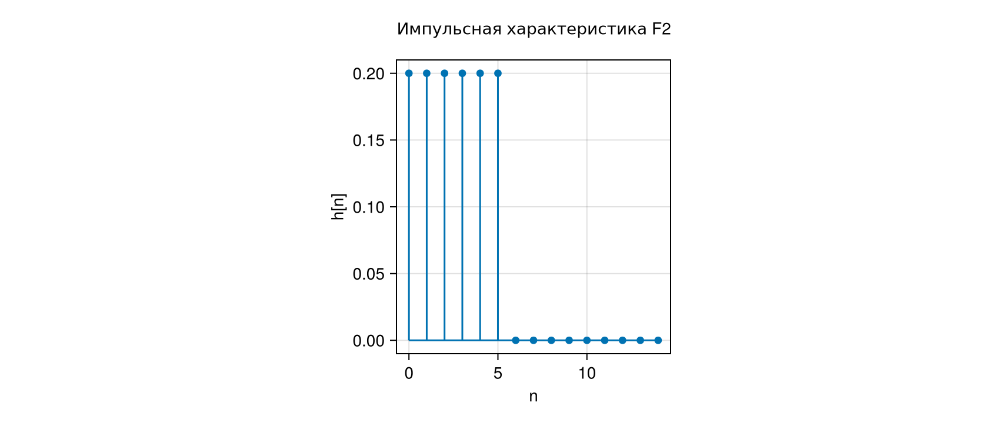

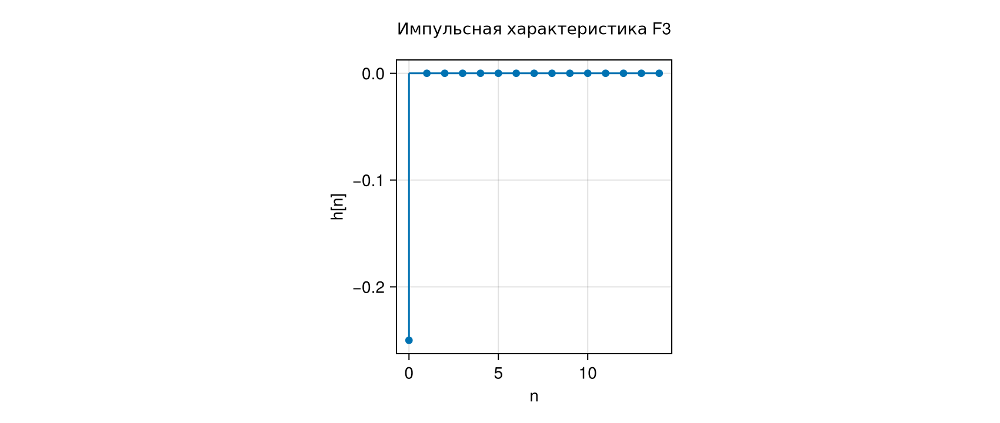

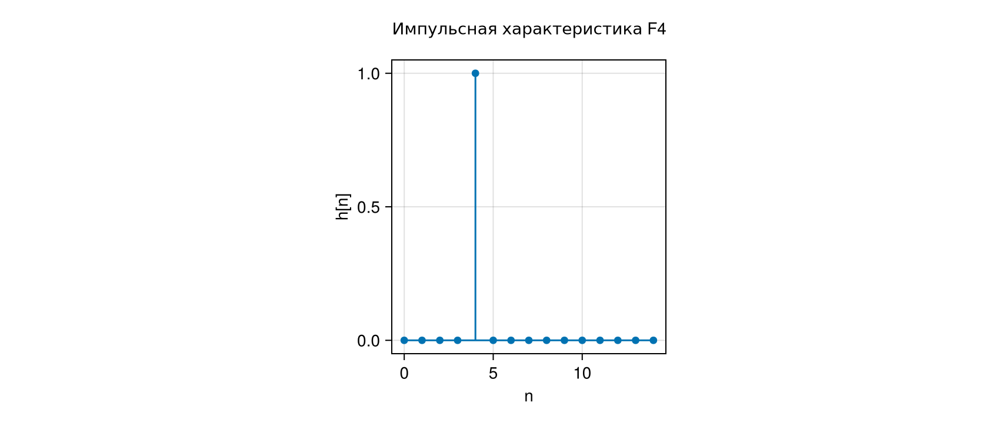

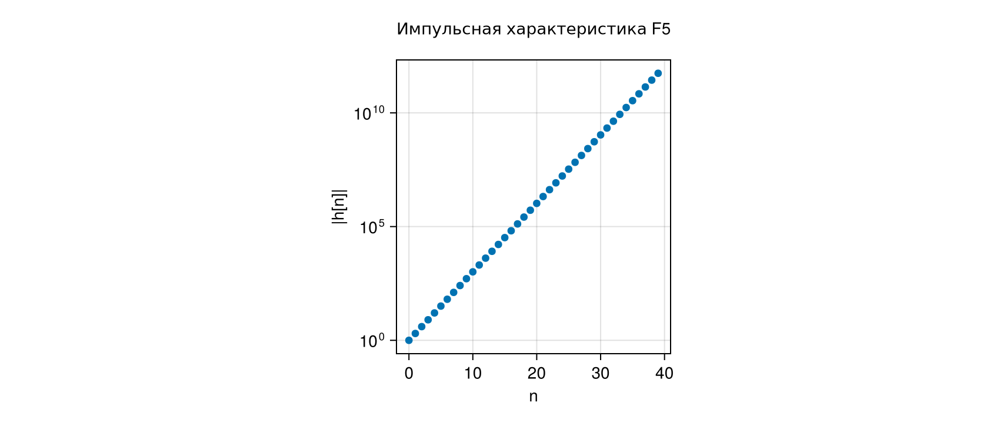

...

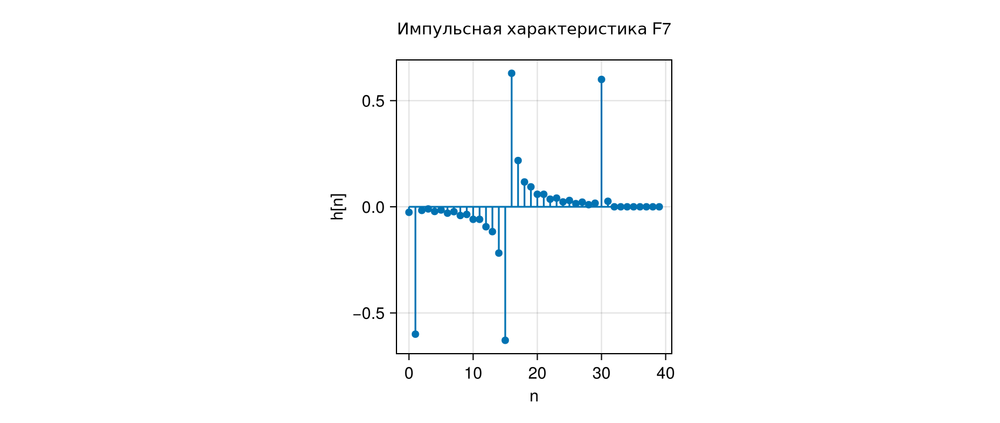

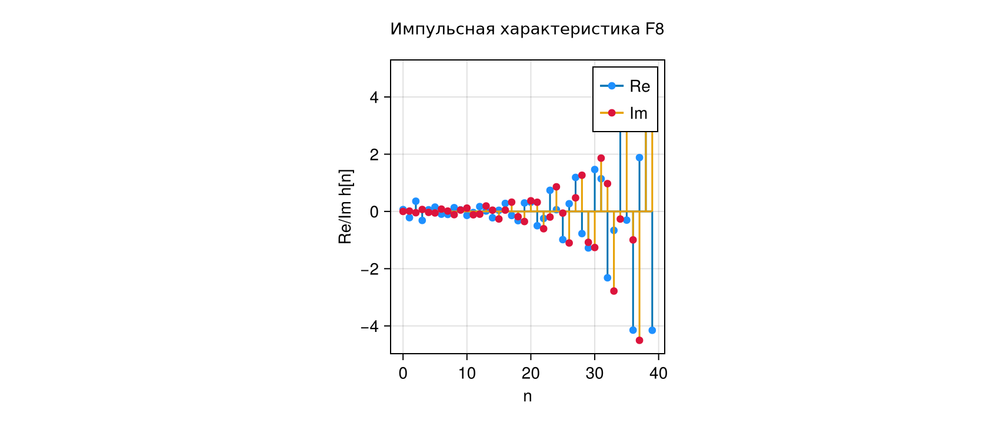

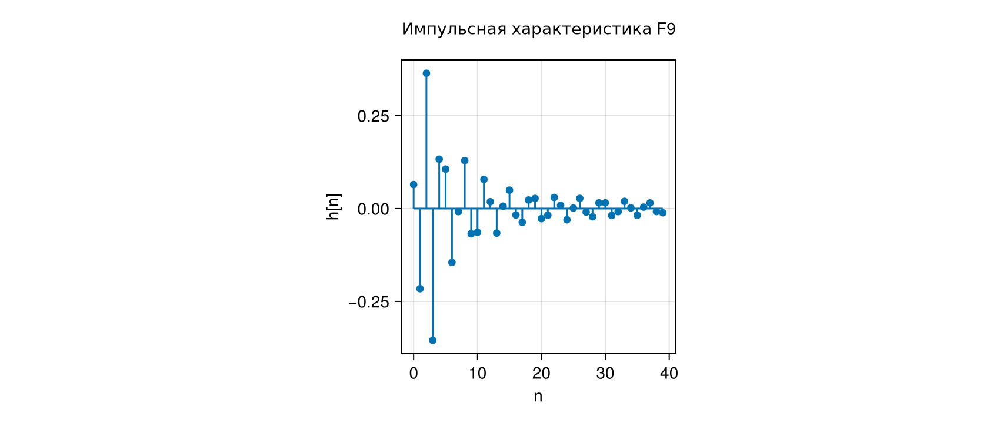

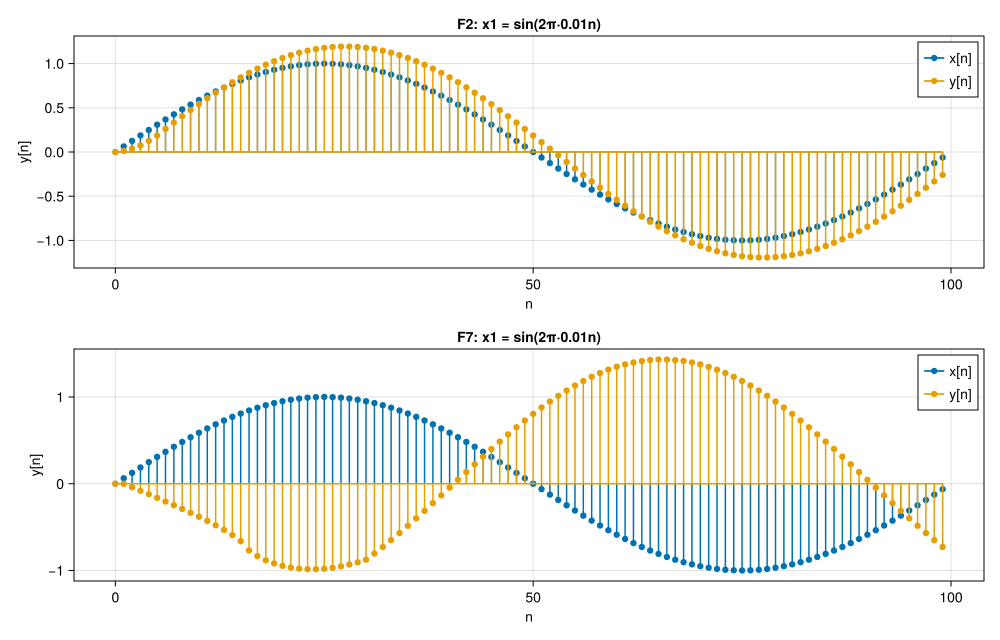

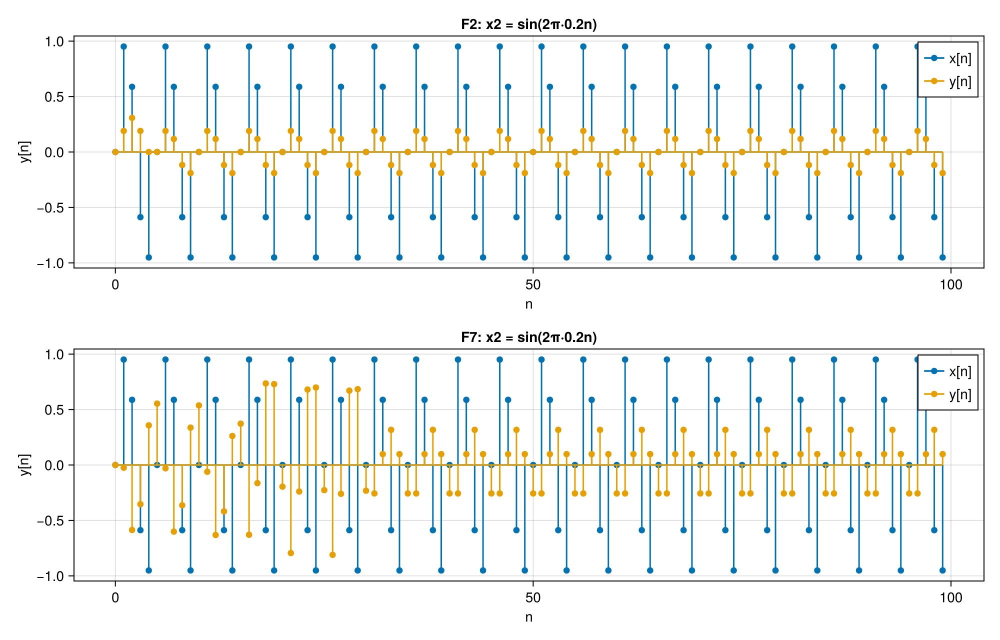

In [ ]:
using LinearAlgebra
using CairoMakie

let

# 2.2. Дискретные LTI-системы
# --- Модели: y[n] = Σb·x[n-i] − Σa·y[n-i], a[1] = 1;  F6 = |x|/2 (нелинейная) ---
b7 = [-0.026, -0.6, -0.017, -0.01, -0.022, -0.015, -0.03, -0.023, -0.041, -0.036,
      -0.059, -0.059, -0.094, -0.117, -0.218, -0.629, 0.629, 0.218, 0.117, 0.094,
       0.059, 0.059, 0.036, 0.041, 0.023, 0.03, 0.015, 0.022, 0.01, 0.017, 0.6, 0.026]
b8 = [0.0646, -0.1235, 0.1949, -0.1949, 0.1235, -0.0646]
a8 = [1.0 + 0.0im, 1.4576 - 0.1880im, 2.3598 - 0.2122im,
      1.8195 - 0.1694im, 1.0772 - 0.0556im, 0.3218]
a9 = [1.0, 1.4277, 2.1448, 1.5880, 0.9051, 0.2682]

# Решатель разностного уравнения при нулевых начальных условиях (y[n] = 0 при n < 1).
    y = zeros(promote_type(eltype(x), eltype(b), eltype(a)), length(x))
    for n in eachindex(y)
        y[n] = sum(b[i+1] * x[n-i] for i in 0:length(b)-1 if n > i; init=0) -
               sum(a[i+1] * y[n-i] for i in 1:length(a)-1 if n > i; init=0)
    end
    y
end

sys = Dict(
    "F1" => ([1.0], [1.0]), "F2" => (fill(1/5, 6), [1.0]),
    "F3" => ([-0.25], [1.0]), "F4" => ([0, 0, 0, 0, 1.0], [1.0]),
    "F5" => ([1.0], [1.0, -2.0]), "F7" => (b7, [1.0]),
    "F8" => (b8, a8), "F9" => (b8, a9),
)
names  = ["F1", "F2", "F3", "F4", "F5", "F6", "F7", "F8", "F9"]
iir    = ["F5", "F8", "F9"]                                 # БИХ
op(nm, x) = nm == "F6" ? abs.(x) ./ 2 : simulate(sys[nm][1], sys[nm][2], x)

# п.1–2. Линейность T{ax1+bx2}=aT{x1}+bT{x2}  и  ТИВ T{x[n-k]}=y[n-k]
check(nm) = begin
    N, k = 100, 7
    a, b = 0.7, -1.3
    x1, x2 = randn(N), randn(N)
    lhs = op(nm, a .* x1 .+ b .* x2); rhs = a .* op(nm, x1) .+ b .* op(nm, x2)
    lin = maximum(abs.(lhs .- rhs)) <= 1e-9 * maximum(abs.(lhs))
    x = randn(N); y = op(nm, x); ref = [zeros(k); y[1:end-k]]
    tiv = maximum(abs.(op(nm, [zeros(k); x[1:end-k]]) .- ref)) <= 1e-9 * maximum(abs.(ref))
    (lin, tiv)
end

println("\n" * "="^78)
println("п.1–2  Линейность и инвариантность во времени:")
for nm in names
    lin, tiv = check(nm)
    println("  ", rpad(nm, 5), "линейна=", rpad(lin ? "да" : "НЕТ", 6), "  ТИВ=", tiv ? "да" : "НЕТ")
end
println("  F6 нелинейна: |a·x1 + b·x2|/2 ≠ a|x1|/2 + b|x2|/2;  ТИВ выполняется (система без памяти)")

# п.3. Импульсные характеристики
println("\nп.3  Импульсные характеристики h[n] = T{δ[n]}:")
d = zeros(200); d[1] = 1
h = Dict(nm => op(nm, d) for nm in names)
Nmax = Dict(nm => nm in ("F1", "F2", "F3", "F4", "F6") ? 15 : 40 for nm in names)

for nm in names
    N = Nmax[nm]; nv = collect(0:N-1); hv = h[nm][1:N]
    println("  h[$nm](0..$(min(N, 6)-1)) = ", round.(real.(h[nm][1:min(N, 6)]), digits=4))
    fig = Figure(size=(850, 360)); Label(fig[0, 1], "Импульсная характеристика $nm")
    if nm == "F8"
        ax = Axis(fig[1, 1]; xlabel="n", ylabel="Re/Im h[n]")
        stem!(ax, nv, real.(hv); color=:dodgerblue, label="Re")
        stem!(ax, nv, imag.(hv); color=:crimson, label="Im")
    elseif nm == "F5"
        hv = abs.(hv); ax = Axis(fig[1, 1]; xlabel="n", ylabel="|h[n]|", yscale=log10)
        stem!(ax, nv, hv)
    else
        ax = Axis(fig[1, 1]; xlabel="n", ylabel="h[n]")
        stem!(ax, nv, real.(hv))
    end
    nm == "F8" && axislegend(ax, position=:rt)
    display(fig)
end

# п.4. Устойчивость по полюсам характеристического многочлена
println("\nп.4  Устойчивость:")
poles(a) = begin
    n = length(a) - 1; n == 0 && return ComplexF64[]
    A = zeros(ComplexF64, n, n); A[2:n, 1:n-1] .= I(n - 1)
    for j in 1:n; A[j, n] = -a[n + 2 - j] / a[1]; end
    eigvals(A)
end
for nm in iir
    b, a = sys[nm]
    r = maximum(abs.(poles(a)))
    hh = abs.(op(nm, d))
    println("  $nm: max|z| = ", round(r, digits=4), "  =>  ", r < 1 ? "устойчива" : "не устойчива",
            "   (|h[0]| = ", round(hh[1], digits=4), ", |h[9]| = ", round(hh[10], digits=4),
            ", |h[39]| = ", round(hh[40], sigdigits=4), ", |h[199]| = ", round(hh[200], sigdigits=4), ")")
end
println("  F1–F4, F7: КИХ, конечная сумма |h| => устойчивы;  F6: |y|≤|x| => устойчива")

# п.5. Гармоники через F2 и F7
println("\nп.5  Прохождение гармоник через F2 и F7:")
fresp(b, a, f) = sum(b[i+1] * exp(-2π * im * f * i) for i in 0:length(b)-1) /
                 sum(a[i+1] * exp(-2π * im * f * i) for i in 0:length(a)-1)
# симметрия b: F2 — симметричная (чистая задержка), F7 — антисимметричная (−90°)
gsym(b) = all(isapprox(b[i], b[end+1-i]) for i in eachindex(b)) ? "симметричная" :
          all(isapprox(b[i], -b[end+1-i]) for i in eachindex(b)) ? "антисимметричная" : "нет"
println("  b для F2: $(gsym(sys["F2"][1]))  =>  линейная фаза, задержка (6-1)/2 = 2.5 отсч.")
println("  b для F7: $(gsym(b7))  =>  фазовый сдвиг −π/2 (четверть периода) + задержка (32-1)/2 = 15.5 отсч.")
println("  модель линейной фазы: φ2(f) = −2π·f·2.5,   φ7(f) = −π/2 − 2π·f·15.5")
for (nm, f) in (("F2", 0.01), ("F2", 0.2), ("F7", 0.01), ("F7", 0.2))
    b, a = sys[nm]
    H  = fresp(b, a, f)
    φm = nm == "F2" ? -2π * f * 2.5 : -π / 2 - 2π * f * 15.5
    Δ  = angle(exp(im * (angle(H) - φm)))      # остаток 0 (или ±π на смене знака АЧХ)
    println("  $nm: f = $f  |H| = ", round(abs(H), digits=6),
            "  arg H = ", round(angle(H), digits=6), " рад = ", round(angle(H) / (2π * f), digits=3),
            " отсч.   остаток фазы = ", round(Δ, digits=4), " рад")
end

ns = 0:99
for (lbl, x) in (("x1 = sin(2π·0.01n)", sin.(2π .* 0.01 .* ns)),
                 ("x2 = sin(2π·0.2n)",  sin.(2π .* 0.2  .* ns)))
    y2, y7 = op("F2", x), op("F7", x)
    A = maximum(abs.(x))
    println("  ", lbl, ":  A_вх = ", round(A, digits=4),
            ",  A_вых(F2) = ", round(maximum(abs.(y2[20:end])), digits=4),
            " (отношение ", round(maximum(abs.(y2[20:end])) / A, digits=4), ")",
            ",  A_вых(F7) = ", round(maximum(abs.(y7[40:end])), digits=4),
            " (отношение ", round(maximum(abs.(y7[40:end])) / A, digits=4), ")")
    fig = Figure(size=(1000, 640))
    ax = Axis(fig[1, 1]; title="F2: " * lbl, xlabel="n", ylabel="y[n]")
    stem!(ax, ns, x; label="x[n]"); stem!(ax, ns, y2; label="y[n]"); axislegend(ax)
    ax = Axis(fig[2, 1]; title="F7: " * lbl, xlabel="n", ylabel="y[n]")
    stem!(ax, ns, x; label="x[n]"); stem!(ax, ns, y7; label="y[n]"); axislegend(ax)
    display(fig)
end

println("  |H2| на частоте f = 0.5 (половина частоты Найквиста) ≈ ",
        round(abs(fresp(sys["F2"][1], sys["F2"][2], 0.5)), digits=4),
        ",  |H7(0)| = ", round(abs(fresp(b7, [1.0], 0.0)), digits=6), " (F7 не пропускает постоянную)")

end


## __Требования к отчету__

Отчет должен содержать:
* Титульный лист
* Цель работы
* Процесс выполнения лабораторной работы в виде формул/графиков/скриншотов созданных моделей/описания полученных результатов
* Листинг кода на языке Julia
* Выводы
